In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
# Load dataset
df = pd.read_csv('superstore_sales.csv')
print("Initial shape:", df.shape)
print("\nMissing values in raw data:")
print(df.isnull().sum())

# Clean data by dropping rows where Order Date is null
df_clean = df.dropna(subset=['Order Date']).copy()
df_clean['Order Date'] = pd.to_datetime(df_clean['Order Date'])
df_clean['Year'] = df_clean['Order Date'].dt.year
df_clean['Month'] = df_clean['Order Date'].dt.month
df_clean['YearMonth'] = df_clean['Order Date'].dt.to_period('M')

print("\nCleaned shape:", df_clean.shape)

Initial shape: (10800, 21)

Missing values in raw data:
Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

Cleaned shape: (9994, 24)


In [3]:
# Category Summary
cat_summary = df_clean.groupby('Category')[['Sales', 'Profit']].sum().reset_index()
cat_summary['Profit_Margin (%)'] = (cat_summary['Profit'] / cat_summary['Sales']) * 100
print("Category Summary:\n", cat_summary)

# Sub-Category Summary
subcat_summary = df_clean.groupby('Sub-Category')[['Sales', 'Profit']].sum().reset_index()
subcat_summary['Profit_Margin (%)'] = (subcat_summary['Profit'] / subcat_summary['Sales']) * 100
subcat_summary = subcat_summary.sort_values(by='Profit', ascending=False)
print("\nTop & Bottom Sub-Categories by Profit:\n", subcat_summary)

# Discount Sensitivity Summary
discount_summary = df_clean.groupby('Discount').agg({
    'Sales': 'sum',
    'Profit': ['sum', 'mean', 'count']
}).reset_index()
discount_summary.columns = ['Discount', 'Total_Sales', 'Total_Profit', 'Mean_Profit', 'Count']
discount_summary['Profit_Margin'] = discount_summary['Total_Profit'] / discount_summary['Total_Sales']
print("\nDiscount vs Profit Summary:\n", discount_summary)

Category Summary:
           Category        Sales       Profit  Profit_Margin (%)
0        Furniture  741999.7953   18451.2728           2.486695
1  Office Supplies  719047.0320  122490.8008          17.035158
2       Technology  836154.0330  145454.9481          17.395712

Top & Bottom Sub-Categories by Profit:
    Sub-Category        Sales      Profit  Profit_Margin (%)
6       Copiers  149528.0300  55617.8249          37.195585
13       Phones  330007.0540  44515.7306          13.489327
0   Accessories  167380.3180  41936.6357          25.054700
12        Paper   78479.2060  34053.5693          43.391837
3       Binders  203412.7330  30221.7633          14.857361
5        Chairs  328449.1030  26590.1663           8.095673
14      Storage  223843.6080  21278.8264           9.506113
1    Appliances  107532.1610  18138.0054          16.867517
9   Furnishings   91705.1640  13059.1436          14.240358
7     Envelopes   16476.4020   6964.1767          42.267582
2           Art   27118.

/tmp/ipykernel_2559/1407162062.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_summary, x='Category', y='Profit', ax=axes[0, 0], palette='Blues_d')
/tmp/ipykernel_2559/1407162062.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_bottom_subcat, y='Sub-Category', x='Profit', ax=axes[1, 1], palette='coolwarm')


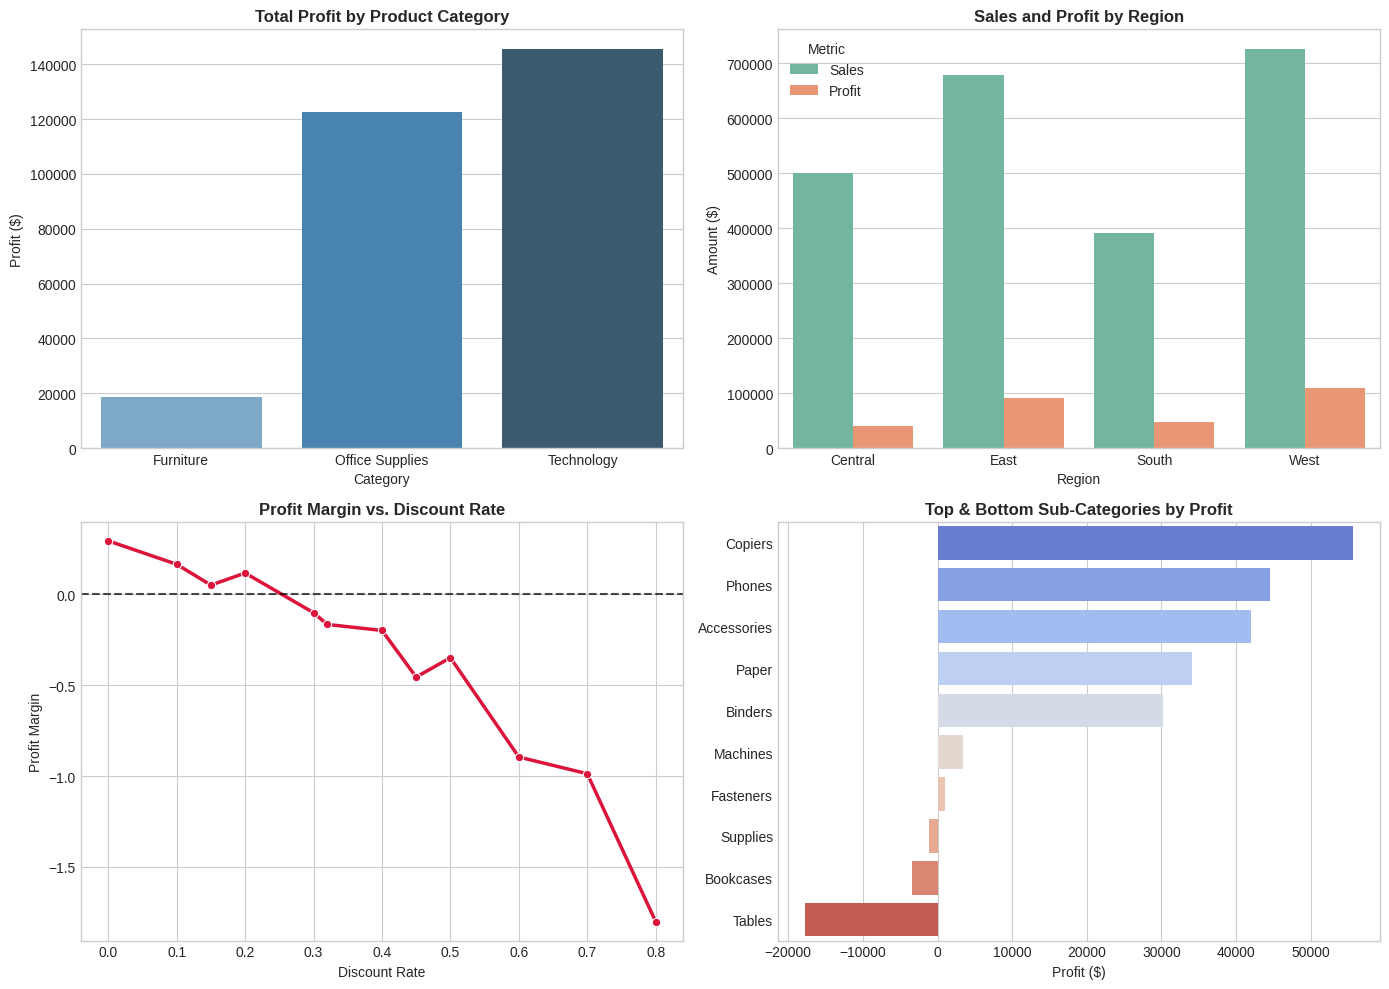

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Category Profit
sns.barplot(data=cat_summary, x='Category', y='Profit', ax=axes[0, 0], palette='Blues_d')
axes[0, 0].set_title('Total Profit by Product Category', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Profit ($)')

# 2. Region Sales vs Profit
region_summary = df_clean.groupby('Region')[['Sales', 'Profit']].sum().reset_index()
region_melted = region_summary.melt(id_vars='Region', value_vars=['Sales', 'Profit'], var_name='Metric', value_name='Amount')
sns.barplot(data=region_melted, x='Region', y='Amount', hue='Metric', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Sales and Profit by Region', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Amount ($)')

# 3. Discount vs Profit Margin
sns.lineplot(data=discount_summary, x='Discount', y='Profit_Margin', ax=axes[1, 0], marker='o', color='crimson', linewidth=2.5)
axes[1, 0].set_title('Profit Margin vs. Discount Rate', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Discount Rate')
axes[1, 0].set_ylabel('Profit Margin')
axes[1, 0].axhline(0, color='black', linestyle='--', alpha=0.7)

# 4. Top/Bottom Sub-Categories
top_bottom_subcat = pd.concat([subcat_summary.head(5), subcat_summary.tail(5)])
sns.barplot(data=top_bottom_subcat, y='Sub-Category', x='Profit', ax=axes[1, 1], palette='coolwarm')
axes[1, 1].set_title('Top & Bottom Sub-Categories by Profit', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Profit ($)')
axes[1, 1].set_ylabel('')

plt.tight_layout()
plt.savefig('superstore_eda_analysis.png', dpi=300)
plt.show()